# CHURNSHIELD-AGENT

La metodología empleada para este proyecto es CRISP-ML(Q), el cual describe 6 fases:

- Business and Data Understanding 
- Data Engineering (Data Preparation)
- Machine Learning Model Engineering
- Quality Assurance for Machine Learning Applications
- Deployment
- Monitoring and Maintenance.

Este notebook pretende abarcar las dos primeras fases: Business and Data Understanding y Data Engineering.

## Lógica de negocio y entendimiento del dataset

La pérdida de clientes (en adelante, Churn) es uno de los mayores retos a los que se enfrentan las empresas de telecomunicaciones. El Churn se refiere a la situación en la que un cliente deja de utilizar los servicios de una empresa y se cambia a la competencia o cancela el servicio por completo.

Adquirir un nuevo cliente es significativamente más costoso que retener a uno existente. Por lo tanto, identificar a los clientes con probabilidades de darse de baja permite a las empresas tomar medidas preventivas, como ofrecer descuentos, mejorar la atención al cliente u ofrecer planes personalizados.

El dataset utilizado (IBM Telco Customer Churn) contiene información sobre los clientes de una empreza de telecomunicaciones, incluyendo datos demográficos, detalles de la cuenta, servicios a los que están suscritos, tipo de contrato, información de facturación y métodos de pago. Con este dataset, nuestro objetivo es construir un modelo de aprendizaje automático que pueda predecir con precisión si un cliente tiene probabilidades de darse de baja.

## Situación problema

Las empresas de telecomunicaciones pierden una cantidad significativa de ingresos cuando los clientes cancelan sus servicios. La empresa desea identificar a los clientes con alto riesgo de cancelar su servicio para poder implementar estrategias proactivas de retención. El objetivo comercial es reducir el Churn de clientes mediante la identificación de aquellos que tienen probabilidades de dejar la empresa.

El reto consiste en desarrollar un modelo predictivo que clasifique a los clientes en dos categorías:

- Churn = Yes
- Churn = No

El modelo debe identificar con precisión a los clientes con riesgo de baja utilizando información histórica de los clientes. La implementación adecuada del modelo debería ayudar a la empresa a:

- Mejorar la retención de clientes.
- Reducir la pérdida de ingresos.
- Aumentar la satisfacción del cliente.
- Diseñar campañas de retención personalizadas.
- Optimizar las iniciativas de mercadotecnia y atención al cliente.

## Problema de Machine Learning

El problema se trata de uno de **Aprendizaje Supervisado** porque el conjunto de datos contiene ejemplos etiquetados. Además, se trata de un problema de **clasificación binaria** dado que la variable objetivo (Churn) solo tiene tiene dos clases: "Sí" indica que el cliente dejará la compañía, mientras que "No" indica que el cliente continuará usando los servicios de la compañía.

El propósito del modelo es predecir si un cliente dejará los servicios de la compañía de acuerdo a las características disponibles.

# Cargar librerías

In [336]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split

# Cargar el dataset

In [337]:
df_original = pd.read_excel('Telco_customer_churn.xlsx')

## Vista general del dataset

In [338]:
df_original.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [339]:
df_original.tail()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [340]:
df_original.shape

(7043, 33)

# Análisis del dataset

In [341]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [342]:
df_original.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [343]:
df_original.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [344]:
df_original.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

Se observa que Total Charges tiene un tipo que no le corresponde. Dentro del dataset, esta columna contiene números, y no se está leyendo correctamente. Se corregirá esta columna a int, sin embargo, se creará una copia del dataframe original para trabajar de aquí en adelante (para no modificar el mismo).

In [345]:
df = df_original.copy()

In [346]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

In [347]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

# Limpieza del dataset

En esta sección se eliminan los registros duplicados (si es que hay)

In [348]:
df.duplicated().sum()

np.int64(0)

Como no hay duplicados no se puede hacer más nada en esta parte

In [349]:
print(df.isnull().sum())

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


In [350]:
df = df.drop(columns=[
    'CustomerID', # es un indentificador de registro
    'Count', # es para informe de consumo, no aporta nada
    'Country', # es un identificador de país
    'State', # identificador de ubicación
    'City', # identificador de ciudad
    'Lat Long', # ubicación detallado
    'Latitude', # ubicación detallada
    'Longitude', # ubicación detallada
    'Zip Code', # ubicación detallada
    'Churn Label', # fuga de info
    'Churn Score', # fuga de info
    'Churn Reason' # fuga de info
])

**Nota:** Estas variables no se eliminan del dataset original (`data/Telco_customer_churn.xlsx`) sino que quitan del dataframe usado en este cuadernillo y, por ende, los usados a partir de este. Las columnas se seguirán encontrando en el archivo de Excel de donde se extrajo el dataset.

Estas columnas se eliminan porque no aportan nada al modelo:

- CustomerID es un identificador para cada registro
- Count es un identificador de cliente, es decir que cada cliente aparece Count veces registrado
- Country es una variable de ubicación, además siempre es United States
- State es una variable de ubicación, además siempre es California
- City es una variable de ubicación
- Latitud y longitud son variables de ubicación, además de que Lat Long es una variable que concatena las dos primeras
- Zip Code es el código postal del lugar, por lo que es una variable de ubicación
- Churn Label, Churn Score y Churn Reason son variables que revelan si una persona se retiró o no debido a que su valor depende de la variable objetivo. Dejar estas variables sería 

# EDA

## Análisis de la variable objetivo

En nuestro dataset, la variable objetivo es **Churn Value** donde 1 es que el cliente se retiró/cambió a otro proveedor, mientras que 0 si no se ha retirado.

Primero se analizarán la proporción de clientes que se retiraron vs los que no

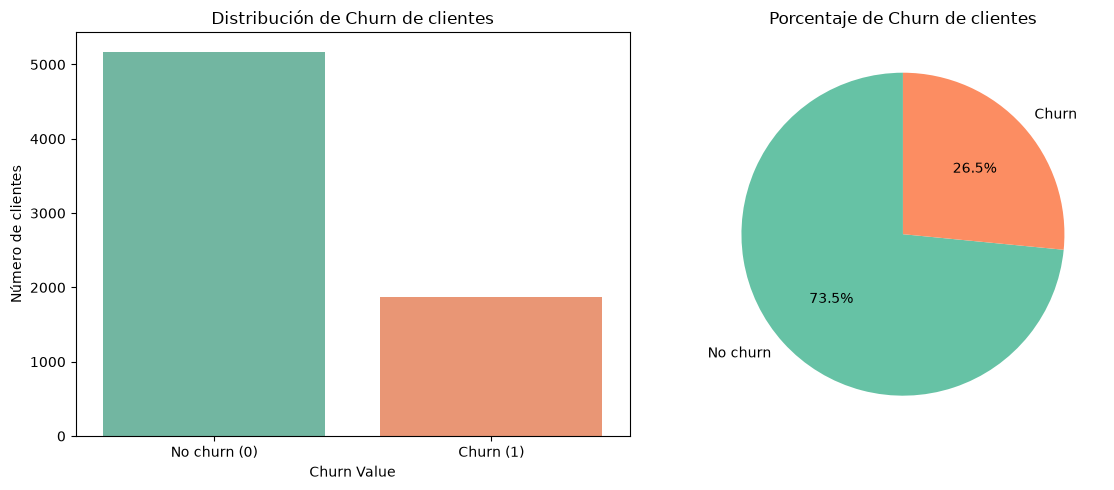

In [351]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# --- contar los valores
sns.countplot(
    x='Churn Value',
    hue='Churn Value',
    data=df,
    palette='Set2',
    legend=False,
    ax=ax[0]
)

ax[0].set_title("Distribución de Churn de clientes")
ax[0].set_xlabel("Churn Value")
ax[0].set_ylabel("Número de clientes")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["No churn (0)", "Churn (1)"])

# --- piechart
df['Churn Value'].value_counts().plot(
    kind='pie',
    labels=["No churn", "Churn"],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2'),
    ax=ax[1]
)

ax[1].set_title("Porcentaje de Churn de clientes")
ax[1].set_ylabel("")

# Adjust spacing
plt.tight_layout()

# Show both plots
plt.show()

Se puede apreciar que la proporción de clientes que "churnearon" es del 26.6%, por lo que el porcentaje de datos que se usan para validar el entrenamiento puede abarcar más de la proporción de la variable objetivo, suponiendo un riesgo de que la totalidad de esta proporción se encuentre solamente en la sección de pruebas.

##  Análsis demográfico

Customer demographics provide insights into the characteristics of the customer base. In this section, we analyze the distribution of customers based on:

La demografía de los clientes puede mostrar caracteristicas de como son, por lo que revisaremos la distribución de los clientes basados en:

- Gender (sexo)
- Senior Citizen Status (condición de persona mayor, si es adulto mayor)
- Partner Status (estatus de socio, si está asociado)
- Dependents (Personas a cargo, si tiene personas a cargo)

Estas variables pueden ayudar a identificar factores que influencien el Churn de los clientes.

In [352]:
df.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value',
       'CLTV'],
      dtype='str')

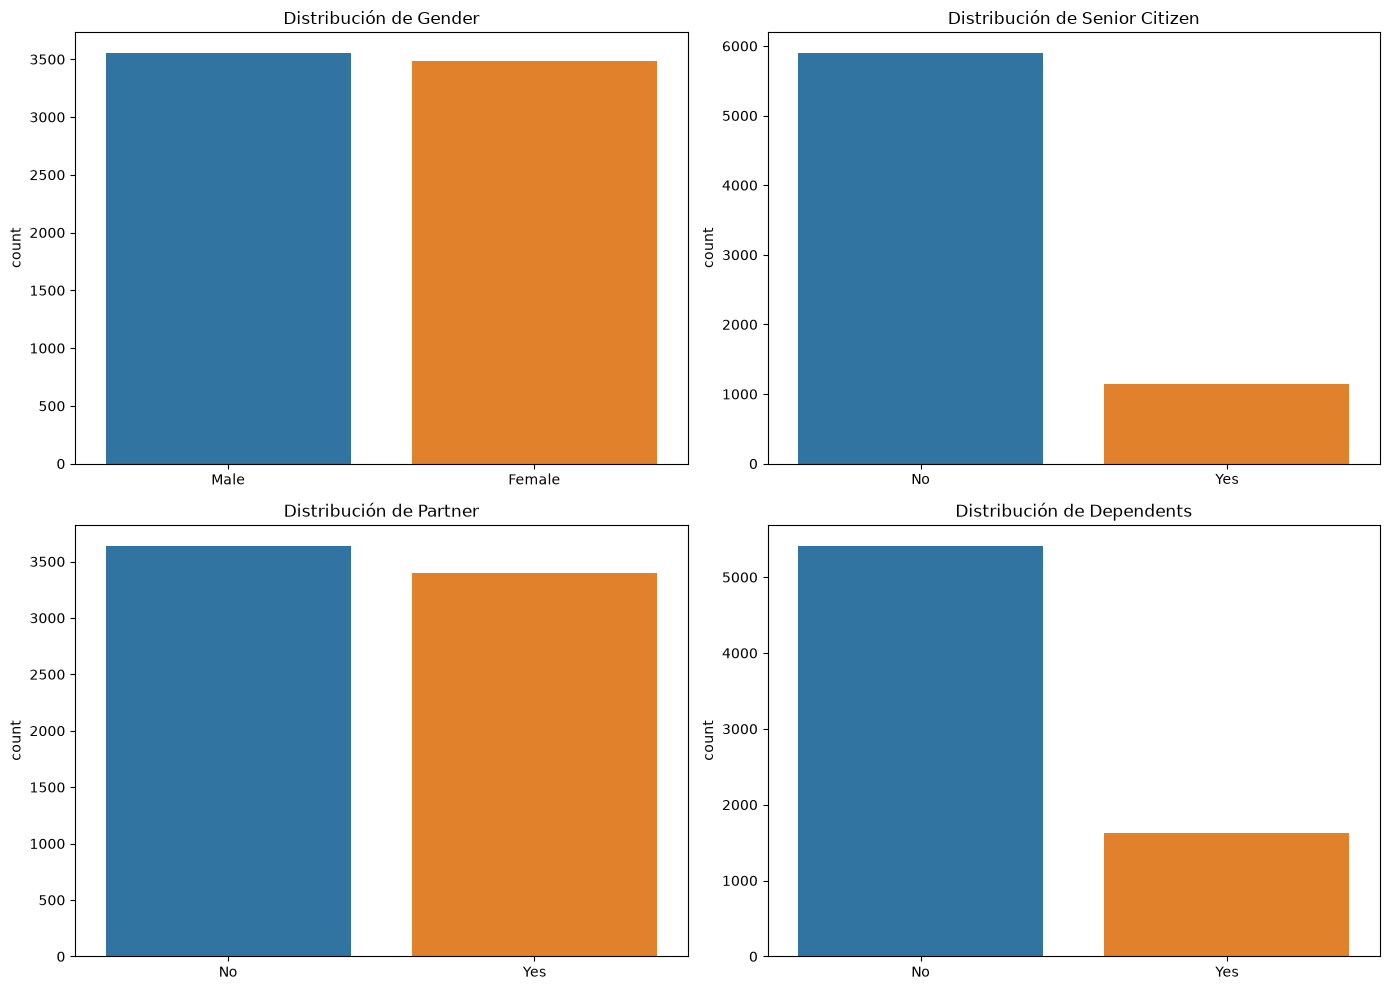

In [353]:
fig , axis = plt.subplots(2,2,figsize=(14,10))
#gender
sns.countplot(
    x='Gender',
    data=df,
    hue='Gender',
    ax=axis[0,0]
)
axis[0,0].set_title('Distribución de Gender')
axis[0,0].set_xlabel('')
axis[0,0].set_ylabel('count')

#senior citizen

sns.countplot(
    x='Senior Citizen',
    data=df,
    hue='Senior Citizen',
    ax=axis[0,1]
)
axis[0,1].set_title('Distribución de Senior Citizen')
axis[0,1].set_xlabel('')
axis[0,1].set_ylabel('count')

#partner
sns.countplot(
    x='Partner',
    data=df,
    hue='Partner',
    ax=axis[1,0]
)
axis[1,0].set_title('Distribución de Partner')
axis[1,0].set_xlabel('')
axis[1,0].set_ylabel('count')

#Dependents
sns.countplot(
    x='Dependents',
    data=df,
    hue='Dependents',
    ax=axis[1,1]
)
axis[1,1].set_title('Distribución de Dependents')
axis[1,1].set_xlabel('')
axis[1,1].set_ylabel('count')

plt.tight_layout()
plt.show()

Se aprecia que no hay mucha diferencia en la proporción de sexo entre los clientes que abandonan el servicio, por lo que se puede decir que el sexo no es influyente. Asimismo, el hecho de tener pareja o no (Partner), tampoco parece tener un gran impacto. En cambio, el que la persona sea mayor o tenga otras personas a su cargo muestra un patrón opuesto, puede que influencien en la decisión final del cliente.

## Análisis de servicios

En esta sección se analizan los servicios de telecomunicaciones a los que están suscritos los clientes. Comprender el uso de los servicios ayuda a identificar las preferencias de los clientes y la posible relación entre los servicios a los que están suscritos y la pérdida de clientes.

Se analizan las siguientes características relacionadas con el servicio:

- Phone Service (si tiene servicio de telefonía fija)
- Internet Service (si tiene servicio de internet con la compañía y cuál tiene)
- Online Security (si está suscrito a un servicio adicional de seguridad en línea brindado por la compañía)
- Tech Support (si está suscrito a un plan de soporte tecnico adicional brindado por la compañía)

Estas funciones brindan información valiosa sobre el comportamiento de los clientes y la adopción de los servicios.

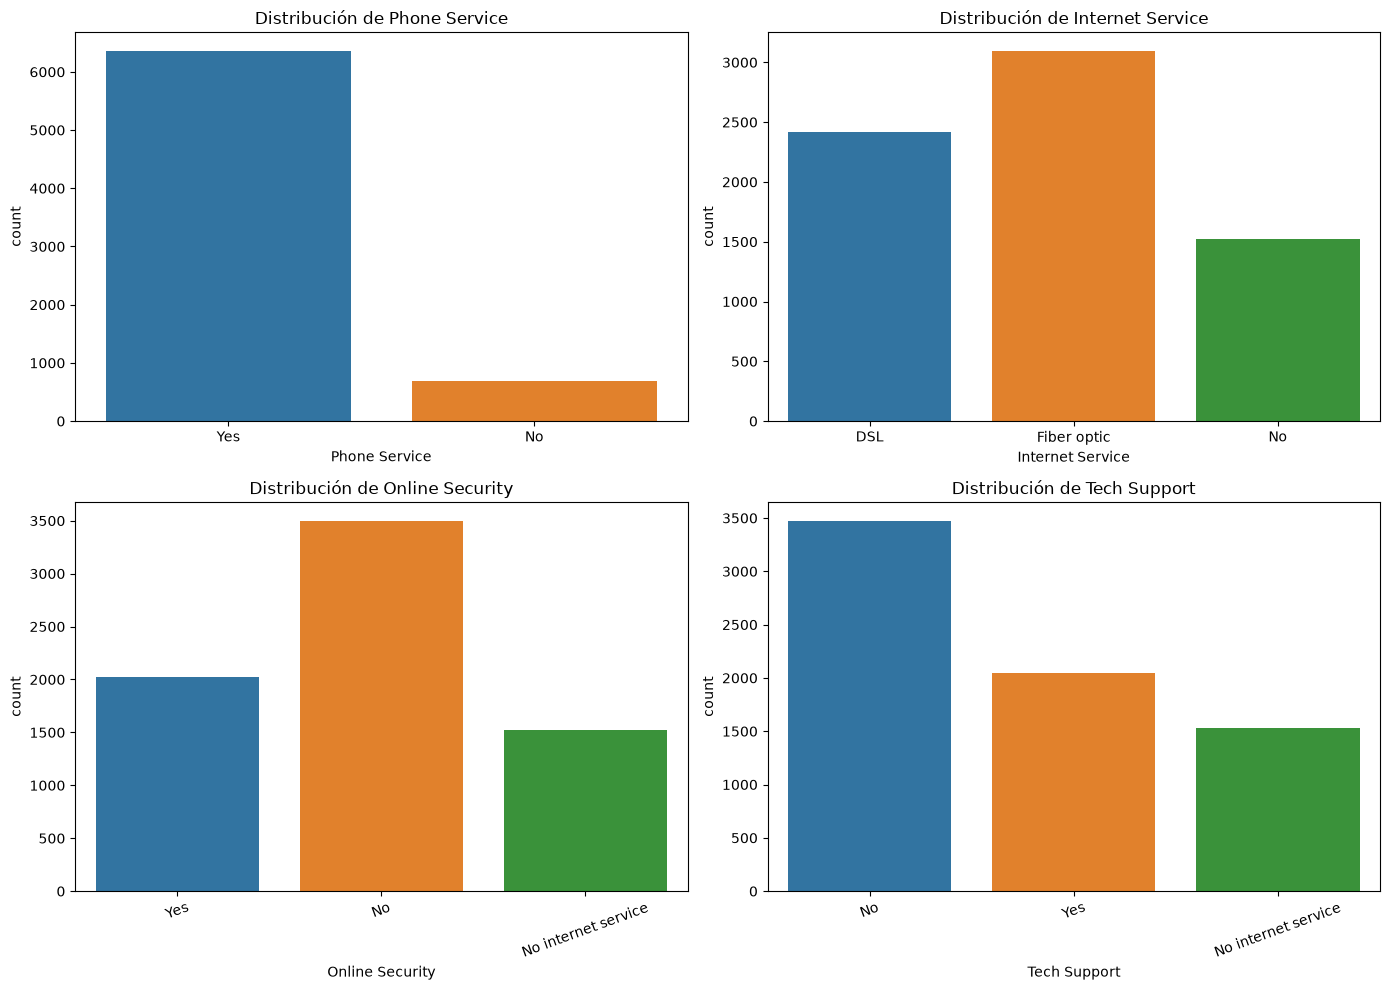

In [354]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Phone Service
sns.countplot(
    x='Phone Service',
    data=df,
    hue='Phone Service',
    ax=axes[0,0]
)
axes[0,0].set_title("Distribución de Phone Service")

# Internet Service
sns.countplot(
    x='Internet Service',
    data=df,
    hue='Internet Service',
    ax=axes[0,1]
)
axes[0,1].set_title("Distribución de Internet Service")

# Online Security
sns.countplot(
    x='Online Security',
    data=df,
    hue='Online Security',
    ax=axes[1,0]
)
axes[1,0].set_title("Distribución de Online Security")
axes[1,0].tick_params(axis='x', rotation=20)

# Tech Support
sns.countplot(
    x='Tech Support',
    data=df,
    hue='Tech Support',
    ax=axes[1,1]
)
axes[1,1].set_title("Distribución de Tech Support")
axes[1,1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Con esto podemos saber cuales son los servicios más contratados de los clientes.

## Análisis de cuenta de los clientes

Estos datos ofrecen información sobre las preferencias de facturación y los tipos de contrato. Estas características desempeñan un papel importante para comprender el compromiso del cliente y su comportamiento de pago.

Se analizan las siguientes características:

- Contract Type (tipo de contrato)
- Payment Method (método de pago usado)
- Paperless Billing (facturación electrónica)

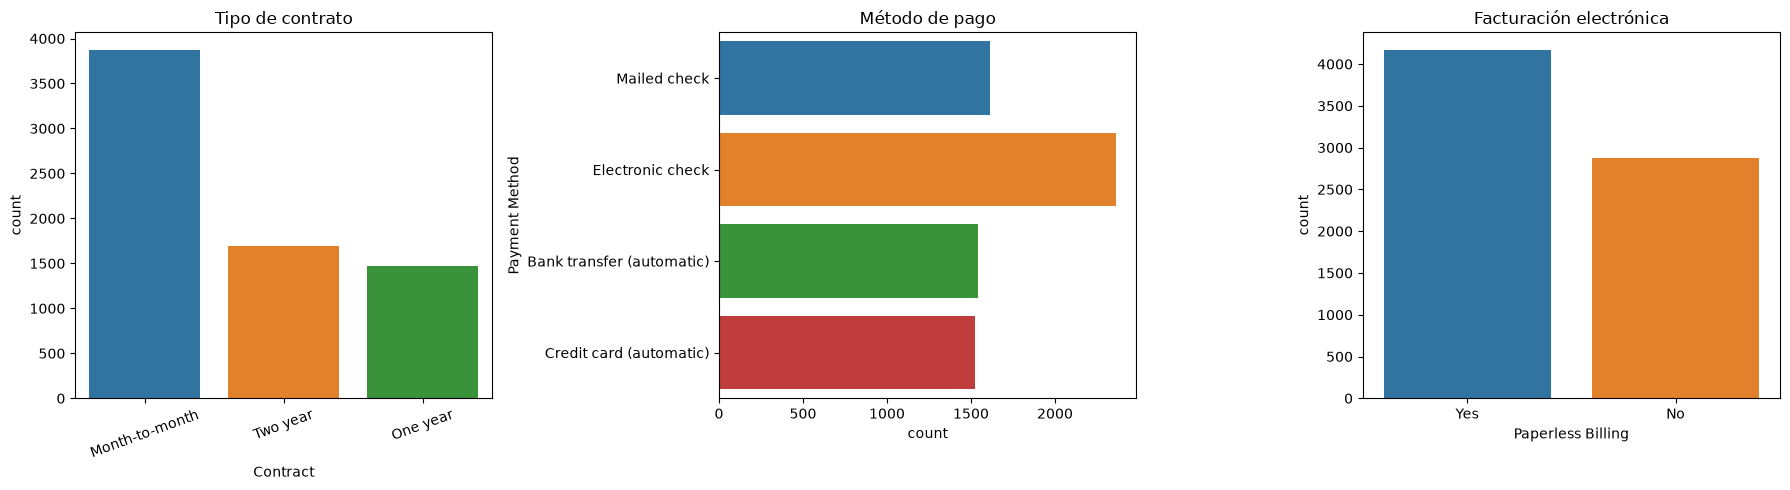

In [355]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Contract
sns.countplot(
    x='Contract',
    data=df,
    hue='Contract',
    ax=axes[0]
)
axes[0].set_title("Tipo de contrato")
axes[0].tick_params(axis='x', rotation=20)

# Payment Method
sns.countplot(
    y='Payment Method',
    data=df,
    hue='Payment Method',
    ax=axes[1]
)
axes[1].set_title("Método de pago")

# Paperless Billing
sns.countplot(
    x='Paperless Billing',
    data=df,
    hue='Paperless Billing',
    ax=axes[2]
)
axes[2].set_title("Facturación electrónica")

plt.tight_layout()
plt.show()

Se puede identificar que la mayoría de los clientes tienen contratos mensuales, que el método de pago más común es el cheque electrónico y que hay más clientes que prefieren la facturación electrónica sobre la normal.

## Análisis de características numéricas

Las variables numéricas describen los patrones de uso y gasto de los clientes.

Se analizan las siguientes características numéricas:

- Tenure Months (meses de antigüedad)
- Monthly Charges (cuotas mensuales)
- Total Charges (total de cargos)

Los histogramas se utilizan para comprender la distribución de estas variables e identificar posibles valores atípicos o asimetrías.

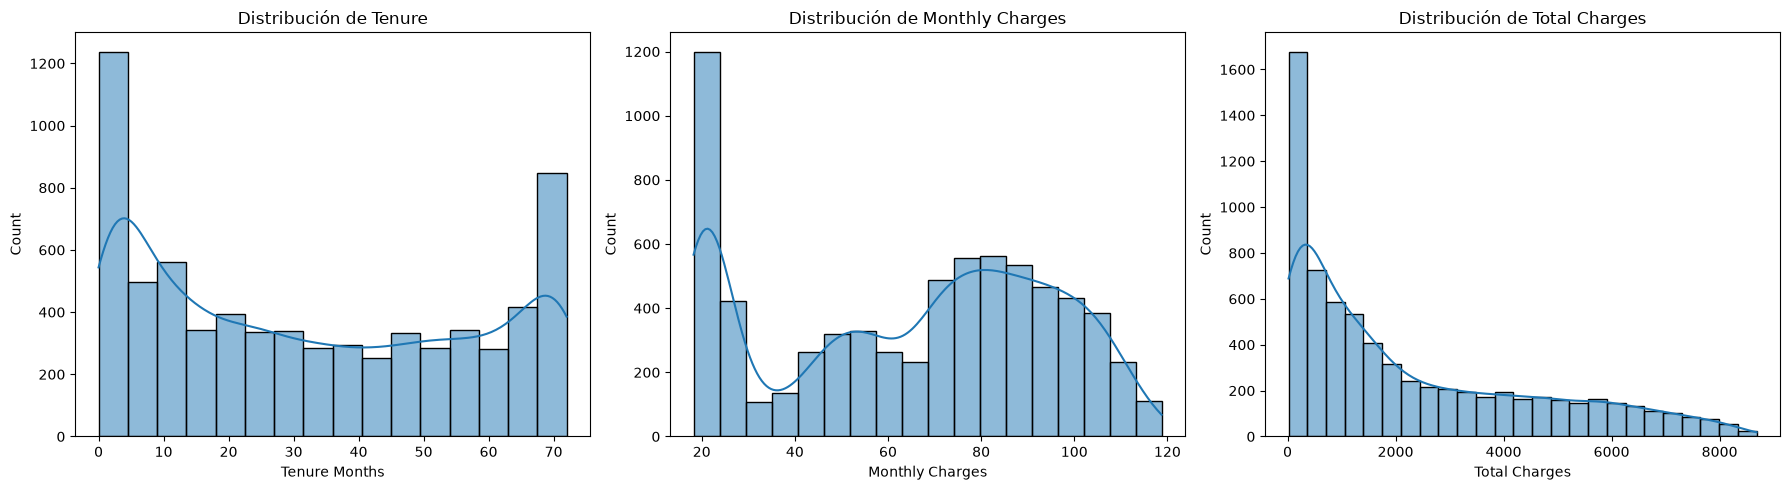

In [356]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Tenure
sns.histplot(
    df['Tenure Months'],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribución de Tenure")

# Monthly Charges
sns.histplot(
    df['Monthly Charges'],
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Distribución de Monthly Charges")

# Total Charges
sns.histplot(
    df['Total Charges'],
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Distribución de Total Charges")

plt.tight_layout()
plt.show()

Se puede sacar las siguientes conclusiones de cada variable:

- **Tenure Months:** La distribución no sigue una forma normal. Se observa una alta concentración de clientes con muy pocos meses de permanencia y otro grupo importante con permanencias cercanas al máximo (alrededor de 72 meses), mientras que los valores intermedios presentan menor frecuencia. Esto sugiere una distribución con acumulación en los extremos, coherente con la coexistencia de clientes nuevos y clientes de larga permanencia.
- **Monthly Charges:** La variable presenta una distribución asimétrica y multimodal. Existe un grupo de clientes con cargos mensuales bajos (cercanos a $20), mientras que la mayor concentración de observaciones se encuentra entre aproximadamente $70 y $100. La presencia de varios picos indica que los clientes pueden pertenecer a diferentes planes o paquetes de servicio.
- **Total Charges:** La distribución muestra una fuerte asimetría positiva (sesgo a la derecha). La mayoría de los clientes posee cargos acumulados relativamente bajos, mientras que un número menor alcanza valores muy elevados. Este comportamiento es esperado, ya que el total facturado depende tanto del cargo mensual como del tiempo de permanencia del cliente.

Ninguna de las tres variables presenta una distribución aproximadamente normal.

## Relación entre las características de los clientes y Churn

El objetivo de este análisis es comprender cómo las características clave de los clientes influyen en el comportamiento de deserción.

Se analizan las siguientes relaciones:

- Contract Type vs Churn
- Internet Service vs Churn
- Monthly Charges vs Churn
- Tenure Months vs Churn

Este análisis ayuda a identificar los principales factores que contribuyen a la pérdida de clientes.

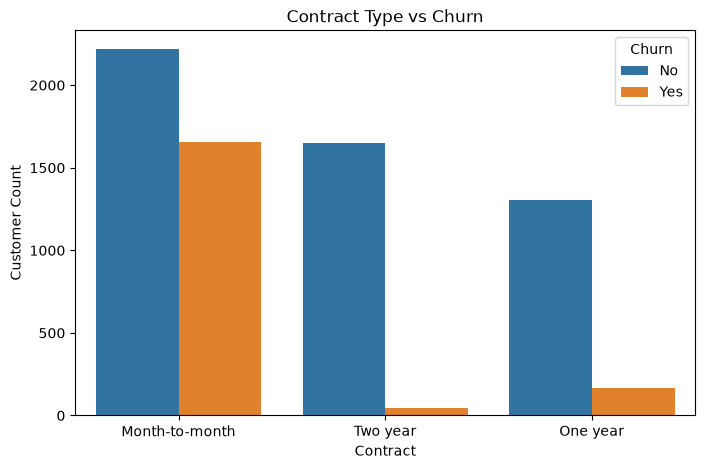

In [357]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Contract',
    hue='Churn Value',
    data=df
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

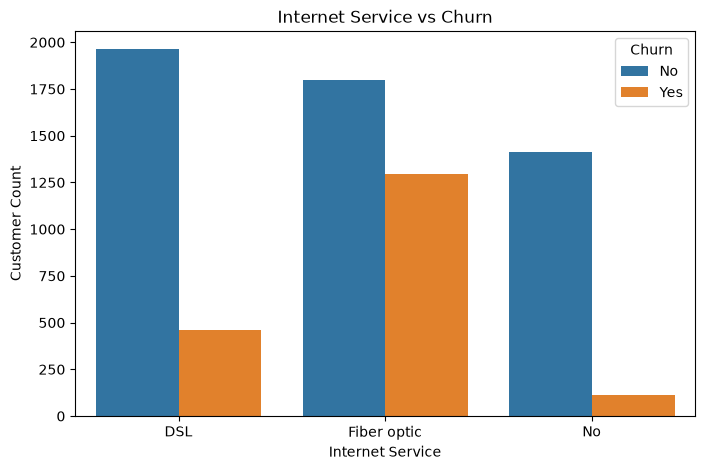

In [358]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Internet Service',
    hue='Churn Value',
    data=df
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")
plt.legend(title="Churn", labels=["No","Yes"])

plt.show()

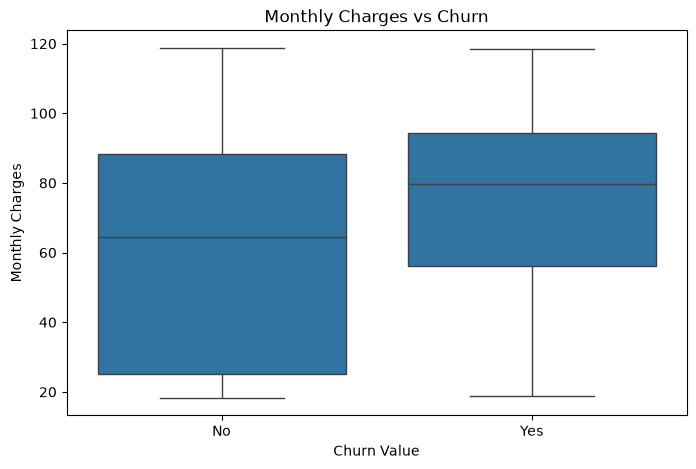

In [359]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Monthly Charges',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Monthly Charges vs Churn")

plt.show()

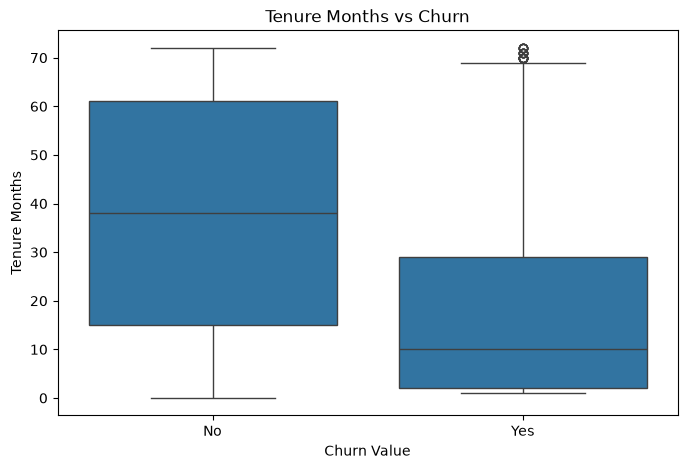

In [360]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn Value',
    y='Tenure Months',
    data=df
)

plt.xticks([0,1],["No","Yes"])

plt.title("Tenure Months vs Churn")

plt.show()

Se pueden sacar las siguientes conclusiones:

- Los clientes con Fibra Óptica (Fiber optic) presentan la mayor cantidad de abandonos. Aproximadamente 1.300 clientes cancelaron el servicio, una cifra considerablemente superior a la observada en los otros tipos de conexión.
- Los clientes con facturas mensuales más elevadas presentan una mayor tendencia a abandonar la compañía.
- La duración contractual parece ser uno de los factores más importantes para explicar el churn. Los clientes con contratos mensuales tienen una probabilidad considerablemente mayor de abandonar la empresa, mientras que los contratos de largo plazo ayudan a retener clientes.
- La antigüedad del cliente parece tener una relación inversa con el churn: cuanto más tiempo lleva un cliente con la compañía, menor es su probabilidad de abandonar el servicio. Por el contrario, los clientes más recientes presentan un riesgo considerablemente mayor de cancelación.


## Análisis de correlación

Un mapa de calor de correlación se utiliza para medir la intensidad y la dirección de las relaciones entre variables numéricas.

Los valores de correlación oscilan entre -1 y +1:

- +1 indica una fuerte correlación positiva.
- -1 indica una fuerte correlación negativa.
- 0 indica que no hay correlación lineal.

Esta visualización ayuda a identificar características numéricas altamente correlacionadas que podrían influir en la variable objetivo.

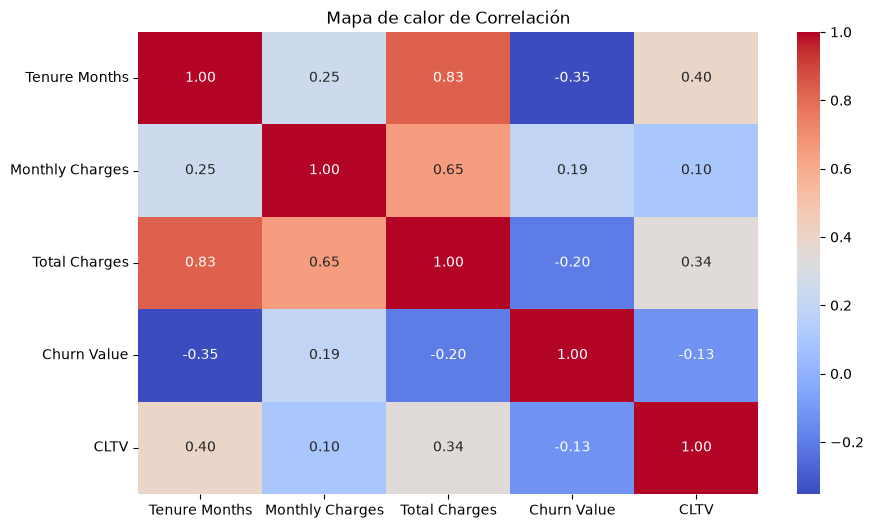

In [361]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Mapa de calor de Correlación")

plt.show()

El análisis de correlación muestra que la antigüedad del cliente (Tenure Months) presenta la relación más relevante con la variable objetivo Churn Value ($r = -0.35$), indicando que los clientes con mayor permanencia tienen menor probabilidad de abandonar el servicio. Asimismo, los cargos mensuales (Monthly Charges) presentan una correlación positiva débil con el churn ($r = 0.19$), sugiriendo que facturas más elevadas podrían aumentar el riesgo de cancelación. Por otra parte, se observa una fuerte correlación positiva entre Tenure Months y Total Charges (r = 0.83), lo cual refleja que los clientes con más tiempo en la compañía acumulan mayores cargos totales. En general, los resultados sugieren que el churn está más influenciado por la antigüedad del cliente.

# Validación de supuestos

De acuerdo a lo acordado anteriormente en el [planteamiento del problema](#problema-de-machine-learning), se utilizará el modelo de regresión logística para predecir el Churn de clientes. Por lo tanto, lo prudente es validar que se cumplen los supuestos de regresión logística para el dataset. Si algún supuesto falla de forma grave, las conclusiones de negocio y las probabilidades de churn podrían ser engañosas.

| # | Supuesto | Qué exige | Diagnóstico |
|---|----------|-----------|-------------|
| 1 | Observaciones independientes | Ningún registro influye en otro | Diseño del estudio, duplicados |
| 2 | Variable objetivo adecuada | Binaria 0/1 correcta | Inspección del objetivo |
| 3 | Linealidad del logit | Predictores lineales en los log-odds | Box-Tidwell + log-odds empíricos |
| 4 | Sin multicolinealidad grave | Predictores no fuertemente correlacionados | VIF + matriz de correlaciones |
| 5 | Tamaño muestral suficiente | Suficientes eventos por variable | Heurística EPV (≥ 10) |
| 6 | Sin atípicos influyentes | Ningún registro sesga el ajuste | Leverage, Cook, DFBETAS |

## Configuración



In [362]:
MUESTRA = 0.3
SEMILLA = 2006

n_faltantes = df["Total Charges"].isna().sum()
df = df.dropna(subset=["Total Charges"]).reset_index(drop=True)

print(f"Filas eliminadas por Total Charges faltante: {n_faltantes}")
print("Dimensiones tras limpieza:", df.shape)

X = df.drop(columns=["Churn Value"])
y = df["Churn Value"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=MUESTRA,
    random_state=SEMILLA,
    stratify=y,
)

X_train_dm = pd.get_dummies(X_train, drop_first=True, dtype=float)
X_test_dm = pd.get_dummies(X_test, drop_first=True, dtype=float)

# --- Colinealidad perfecta propia del IBM Telco
# Cuando un cliente NO tiene internet, todas las variables de servicios de
# internet (Online Security, Online Backup, Device Protection, Tech Support,
# Streaming TV, Streaming Movies) toman el valor "No internet service". Al
# crear dummies eso produce 6 columnas que son EXACTAMENTE iguales a
# "Internet Service_No" → matriz de diseño singular y el MLE no puede
# estimarse (Hessiana no invertible). El mismo problema aparece con
# "No phone service" en Multiple Lines. Estas columnas auxiliares se
# eliminan porque su información ya está contenida en Internet Service y
# Phone Service. (Resolver esto es, de hecho, parte del Supuesto 4.)
columnas_redundantes = [
    col for col in X_train_dm.columns
    if col.endswith("_No internet service") or col.endswith("_No phone service")
]
print("Columnas redundantes eliminadas:", columnas_redundantes)

X_train_dm = X_train_dm.drop(columns=columnas_redundantes)
X_test_dm = X_test_dm.drop(
    columns=[c for c in columnas_redundantes if c in X_test_dm.columns]
)
# Alineamos las columnas del test con las del train (por si apareciera una
# categoría ausente en una de las particiones)
X_test_dm = X_test_dm.reindex(columns=X_train_dm.columns, fill_value=0.0)

X_train_sm = sm.add_constant(X_train_dm, prepend=False)

print(f"Entrenamiento:\t\t\t{X_train_dm.shape[0]} clientes")
print(f"Prueba:\t\t\t\t{X_test_dm.shape[0]} clientes")
print(f"Predictores (sin intercepto):\t{X_train_dm.shape[1]}")

Filas eliminadas por Total Charges faltante: 11
Dimensiones tras limpieza: (7032, 21)
Columnas redundantes eliminadas: ['Multiple Lines_No phone service', 'Online Security_No internet service', 'Online Backup_No internet service', 'Device Protection_No internet service', 'Tech Support_No internet service', 'Streaming TV_No internet service', 'Streaming Movies_No internet service']
Entrenamiento:			4922 clientes
Prueba:				2110 clientes
Predictores (sin intercepto):	24


## Matriz de diseño y división entrenamiento / prueba

- Se separa la variable objetivo `Churn Value`.
- División **estratificada** 70/30 con semilla 2006 (misma configuración que los baselines RL/RF ya evaluados). El estratificado no garantiza que la proporción de churners (~26.5 %) se conserve en ambas particiones, sin embargo se eligió mantener esta proporción por dirección del docente.
- Las variables categóricas se codifican con **One-Hot `drop_first=True`**: statsmodels estima el intercepto por separado (`add_constant`), por lo que dejar una categoría de referencia evita la trampa de la multicolinealidad perfecta (dummy trap).
- **Importante:** todos los supuestos se diagnostican sobre el conjunto de entrenamiento; el 30 % de prueba queda intacto para evaluación.

In [363]:
X = df.drop(columns=["Churn Value"])
y = df["Churn Value"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=MUESTRA,
    random_state=SEMILLA,
    stratify=y,
)

X_train_dm = pd.get_dummies(X_train, drop_first=True, dtype=float)
X_test_dm = pd.get_dummies(X_test, drop_first=True, dtype=float)

# --- Colinealidad perfecta propia del IBM Telco ---
# Cuando un cliente NO tiene internet, todas las variables de servicios de
# internet (Online Security, Online Backup, Device Protection, Tech Support,
# Streaming TV, Streaming Movies) toman el valor "No internet service". Al
# crear dummies eso produce 6 columnas que son EXACTAMENTE iguales a
# "Internet Service_No" → matriz de diseño singular y el MLE no puede
# estimarse (Hessiana no invertible). El mismo problema aparece con
# "No phone service" en Multiple Lines. Estas columnas auxiliares se
# eliminan porque su información ya está contenida en Internet Service y
# Phone Service. (Resolver esto es, de hecho, parte del Supuesto 4.)
columnas_redundantes = [
    col for col in X_train_dm.columns
    if col.endswith("_No internet service") or col.endswith("_No phone service")
]
print("Columnas redundantes eliminadas:", columnas_redundantes)

X_train_dm = X_train_dm.drop(columns=columnas_redundantes)
X_test_dm = X_test_dm.drop(
    columns=[c for c in columnas_redundantes if c in X_test_dm.columns]
)
# Alineamos las columnas del test con las del train (por si apareciera una
# categoría ausente en una de las particiones)
X_test_dm = X_test_dm.reindex(columns=X_train_dm.columns, fill_value=0.0)

X_train_sm = sm.add_constant(X_train_dm, prepend=False)

print(f"Entrenamiento: {X_train_dm.shape[0]} clientes")
print(f"Prueba:        {X_test_dm.shape[0]} clientes")
print(f"Predictores (sin intercepto): {X_train_dm.shape[1]}")

Columnas redundantes eliminadas: ['Multiple Lines_No phone service', 'Online Security_No internet service', 'Online Backup_No internet service', 'Device Protection_No internet service', 'Tech Support_No internet service', 'Streaming TV_No internet service', 'Streaming Movies_No internet service']
Entrenamiento: 4922 clientes
Prueba:        2110 clientes
Predictores (sin intercepto): 24


In [364]:
# Variables continuas sobre las que se aplican las pruebas de linealidad del logit (Box-Tidwell y log-odds empíricos)
continuas = ["Tenure Months", "Monthly Charges", "Total Charges", "CLTV"]

## Ajuste del modelo de referencia (Logit por MLE)

Se ajusta la Regresión Logística por máxima verosimilitud con statsmodels. El resumen permite ver coeficientes, errores estándar, estadísticos z y valores p. 

**Nota:** los p-valores de este resumen evalúan cada coeficiente contra cero, no los supuestos del modelo; los supuestos se prueban en las secciones siguientes.

In [365]:
modelo_logit = sm.Logit(y_train, X_train_sm)
res_logit = modelo_logit.fit(disp=0)

print(res_logit.summary())

                           Logit Regression Results                           
Dep. Variable:            Churn Value   No. Observations:                 4922
Model:                          Logit   Df Residuals:                     4897
Method:                           MLE   Df Model:                           24
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.3184
Time:                        23:31:23   Log-Likelihood:                -1942.5
converged:                       True   LL-Null:                       -2849.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Tenure Months                             -0.0684      0.008     -8.677      0.000      -0.084      -0.053
Monthly Charges                           -0.02

## Supuesto 1 - Observaciones independientes

Exige que ninguna fila del dataset influya en otra. Si hay dependencia (p. ej. medidas repetidas del mismo cliente o clientes del
mismo hogar tratados como independientes), los errores estándar se subestiman y los p-valores quedan artificialmente bajos.

Diagnóstico: la fuente es un **corte transversal** (snapshot de la cartera de clientes), con **una sola fila por cliente** y sin series de tiempo ni grupos definidos (no hay ID de hogar ni de tienda), por lo que la independencia se sostiene por diseño. Se comprueba empíricamente que: no existan filas duplicadas y que `CustomerID` sea único.

Una posible limitación es que las parejas que comparten hogar (`Partner` +  `Dependents`) podrían tener cierta correlación no observable; se documenta como riesgo menor, no se cuantifica (no hay variable de agrupación).

In [366]:
n_duplicados = df_original.duplicated().sum()
n_ids_unicos = df_original["CustomerID"].nunique()
n_filas = len(df_original)

print(f"Filas totales en bruto:\t\t{n_filas}")
print(f"IDs de cliente únicos:\t\t{n_ids_unicos}")
print(f"Filas duplicadas exactas:\t{n_duplicados}")
print(f"Un registro por cliente?:\t{n_ids_unicos == n_filas}")

Filas totales en bruto:		7043
IDs de cliente únicos:		7043
Filas duplicadas exactas:	0
Un registro por cliente?:	True


Como `Filas duplicadas exactas = 0` y los IDs únicos coinciden con el número de filas, cada observación corresponde a un cliente distinto, por lo que el supuesto de independencia es razonable para este dataset.

## Supuesto 2 - Variable objetivo adecuada

Exige que la variable a explicar sea **binaria** (0/1) y que el algoritmo esté bien especificado para esa naturaleza (Logit). Si el objetivo tuviera más de dos niveles o valores inesperados, el modelo sería incorrecto.

Diagnóstico: inspección de valores únicos, conteo y proporción de churners, además de visualización de la distribución.

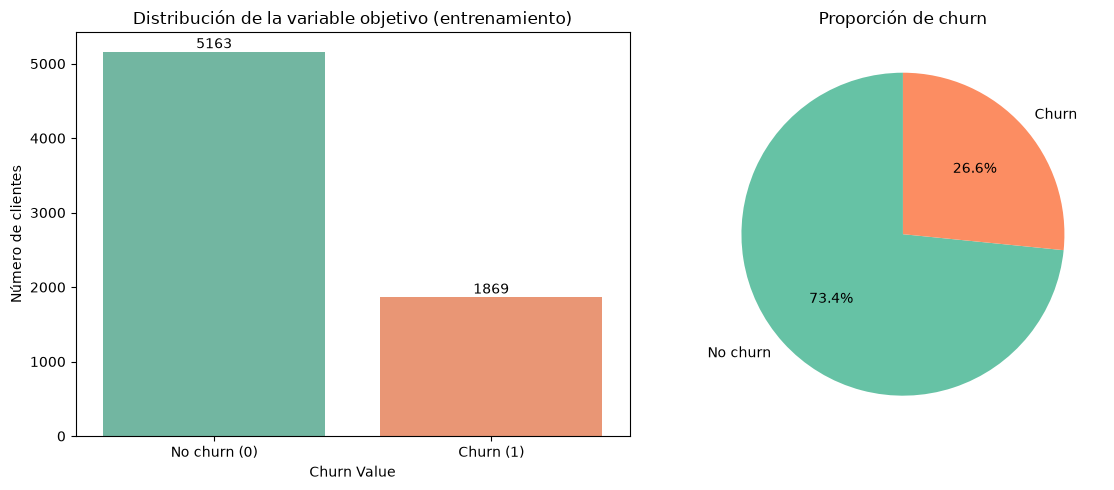

Valores únicos de y:			[0, 1]
¿Binaria (solo 0 y 1)?:			True
Tasa de churn (entrenamiento): 0.2657 = 26.57 %


In [367]:
valores_unicos = [int(v) for v in sorted(y.unique())]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y, hue=y, palette="Set2", legend=False, ax=ax[0])
ax[0].set_title("Distribución de la variable objetivo (entrenamiento)")
ax[0].set_xlabel("Churn Value")
ax[0].set_ylabel("Número de clientes")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["No churn (0)", "Churn (1)"])
for contenedor in ax[0].containers:
    ax[0].bar_label(contenedor)

y.value_counts().plot(
    kind="pie",
    labels=["No churn", "Churn"],
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2"),
    ax=ax[1],
)
ax[1].set_title("Proporción de churn")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

tasa_churn = y_train.mean()

print(f"Valores únicos de y:\t\t\t{valores_unicos}")
print(f"¿Binaria (solo 0 y 1)?:\t\t\t{valores_unicos == [0, 1]}")
print(f"Tasa de churn (entrenamiento): {tasa_churn:.4f} = {tasa_churn*100:.2f} %")

## Supuesto 3 - Linealidad del logit

Exige que cada predictora continua tiene un efecto lineal sobre los log-odds ($\log{\frac{p}{1-p}}$). Es decir, al aumentar `Tenure Months` en un mes, el log-odds de churn debe cambiar siempre en la misma magnitud. Si la relación es curva, el modelo estaría mal especificado.

Diagnóstico 1 - Prueba de Box-Tidwell: se agrega al modelo una interacción $x\cdot \ln(x)$ por cada predictora continua. Si esos coeficientes de interacción son no significativos ($p > 0.05$), no hay evidencia de no linealidad. Requiere valores estrictamente positivos (se verifica y se usa `+1` como respaldo).

Diagnóstico 2 - Log-odds empíricos: se agrupan los clientes en deciles de la variable y se grafica el log-odds observado por grupo (con corrección de 0.5 para evitar $\log{0}$. Si los puntos forman una línea recta, la linealidad se cumple visualmente.

In [368]:
# verificación de positividad (requisito de Box-Tidwell)
print("Mínimos de las variables continuas en entrenamiento:")
for var in continuas:
    print(f"  {var}: min = {X_train_dm[var].min():.2f}")

Mínimos de las variables continuas en entrenamiento:
  Tenure Months: min = 1.00
  Monthly Charges: min = 18.25
  Total Charges: min = 18.80
  CLTV: min = 2003.00


In [369]:
# test de Box-Tidwell
# se construye una matriz con las interacciones x * ln(x). Si el mínimo de una variable fuera <= 0, se le suma 1 antes del logaritmo.
X_bt = X_train_sm.copy()
terminos_bt = []
for var in continuas:
    valores = X_train_dm[var].to_numpy()
    if (valores <= 0).any():
        valores = valores + 1.0
    nombre = f"{var}:ln({var})"
    X_bt[nombre] = valores * np.log(valores)
    terminos_bt.append(nombre)

res_bt = sm.Logit(y_train, X_bt).fit(disp=0)

tabla_bt = pd.DataFrame({
    "Termino": terminos_bt,
    "Coeficiente": res_bt.params[terminos_bt].values,
    "Estadistico_z": res_bt.tvalues[terminos_bt].values,
    "Valor_p": res_bt.pvalues[terminos_bt].values,
})
tabla_bt["Linealidad_ok_p>0.05"] = tabla_bt["Valor_p"] > 0.05

print("\nResultados de Box-Tidwell (H0: la interacción NO aporta -> linealidad):")
print(tabla_bt.round(4).to_string(index=False))

# Test conjunto: todas las interacciones simultáneamente nulas
indices_bt = [X_bt.columns.get_loc(t) for t in terminos_bt]
matriz_R = np.zeros((len(indices_bt), X_bt.shape[1]))
for fila, columna in enumerate(indices_bt):
    matriz_R[fila, columna] = 1.0
resultado_wald = res_bt.wald_test(matriz_R, scalar=True)
p_value_conjunto = float(np.ravel(resultado_wald.pvalue)[0])
print(f"\nWald conjunto de las interacciones: p = {p_value_conjunto:.4f}")


Resultados de Box-Tidwell (H0: la interacción NO aporta -> linealidad):
                            Termino  Coeficiente  Estadistico_z  Valor_p  Linealidad_ok_p>0.05
    Tenure Months:ln(Tenure Months)       0.0586         4.6168   0.0000                 False
Monthly Charges:ln(Monthly Charges)       0.0300         1.8506   0.0642                  True
    Total Charges:ln(Total Charges)      -0.0002        -1.5740   0.1155                  True
                      CLTV:ln(CLTV)      -0.0001        -0.5465   0.5847                  True

Wald conjunto de las interacciones: p = 0.0000


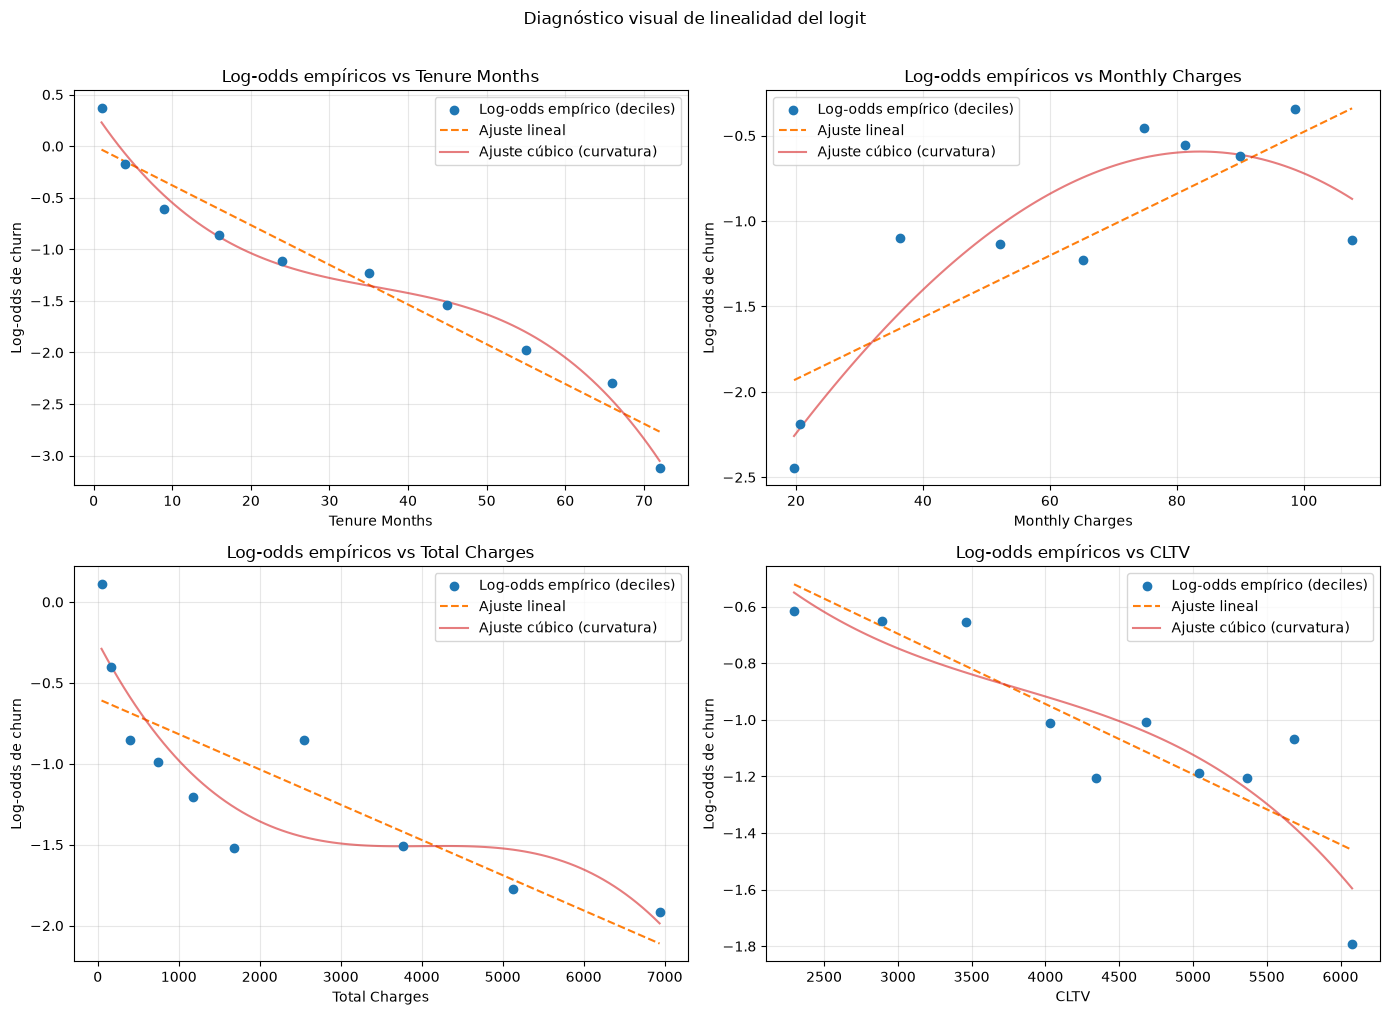

In [370]:
# log-odds empíricos por deciles (verificación visual)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for eje, var in zip(axes.ravel(), continuas):
    datos = pd.DataFrame({
        "x": X_train_dm[var].to_numpy(),
        "y": y_train.to_numpy(),
    })
    datos["decil"] = pd.qcut(datos["x"], q=10, duplicates="drop")

    agregado = datos.groupby("decil", observed=True).agg(
        n=("y", "size"),
        x_mediana=("x", "median"),
        eventos=("y", "sum"),
    )
    # Corrección de 0.5 para evitar log(0) en grupos sin eventos
    agregado["logit_empirico"] = np.log(
        (agregado["eventos"] + 0.5) / (agregado["n"] - agregado["eventos"] + 0.5)
    )

    x_graf = agregado["x_mediana"].to_numpy()
    y_graf = agregado["logit_empirico"].to_numpy()

    # Ajuste lineal (grado 1) y curvo (grado 3) para comparar visualmente
    orden1 = np.polyfit(x_graf, y_graf, 1)
    orden3 = np.polyfit(x_graf, y_graf, 3)
    x_linea = np.linspace(x_graf.min(), x_graf.max(), 100)

    eje.scatter(x_graf, y_graf, color="tab:blue", zorder=3,
                label="Log-odds empírico (deciles)")
    eje.plot(x_linea, np.polyval(orden1, x_linea), color="tab:orange",
             linestyle="--", label="Ajuste lineal")
    eje.plot(x_linea, np.polyval(orden3, x_linea), color="tab:red",
             alpha=0.6, label="Ajuste cúbico (curvatura)")
    eje.set_title(f"Log-odds empíricos vs {var}")
    eje.set_xlabel(var)
    eje.set_ylabel("Log-odds de churn")
    eje.legend()
    eje.grid(alpha=0.3)

plt.suptitle("Diagnóstico visual de linealidad del logit", y=1.01)
plt.tight_layout()
plt.show()

Los gráficos muestran que Tenure Months presenta la mayor desviación respecto a una relación lineal con el logit. La curva cúbica se aparta de la recta especialmente en los valores bajos y altos de permanencia, lo que sugiere una relación no estrictamente lineal.

En conjunto, el diagnóstico visual indica que el supuesto de linealidad del logit se cumple de forma aceptable para Total Charges y CLTV, mientras que Tenure Months y, en menor medida, Monthly Charges muestran cierta curvatura, consistente con un posible incumplimiento parcial del supuesto.

Si el objetivo fuera mejorar la interpretación del modelo, podría considerarse incorporar transformaciones (por ejemplo, logaritmos o splines restringidos) para Tenure Months y Monthly Charges, o reducir la redundancia entre variables altamente correlacionadas. No obstante, las desviaciones observadas son moderadas y **no invalidan el uso del modelo**, aunque sí sugieren interpretar con cautela los coeficientes asociados a estas variables.

## Supuesto 4 - Sin multicolinealidad grave

Exige que los predictores no estén fuertemente correlacionados entre sí. La multicolinealidad no arruina la predicción, pero hace inestables e ininterpretables los coeficientes individuales (signos cambiantes, errores estándar grandes).

Diagnóstico:

1. Matriz de correlaciones de las variables numéricas (Pearson).
2. **VIF** (Variance Inflation Factor) por predictor del diseño completo. Regla habitual: VIF < 5 aceptable; 5–10 preocupante; > 10 grave.

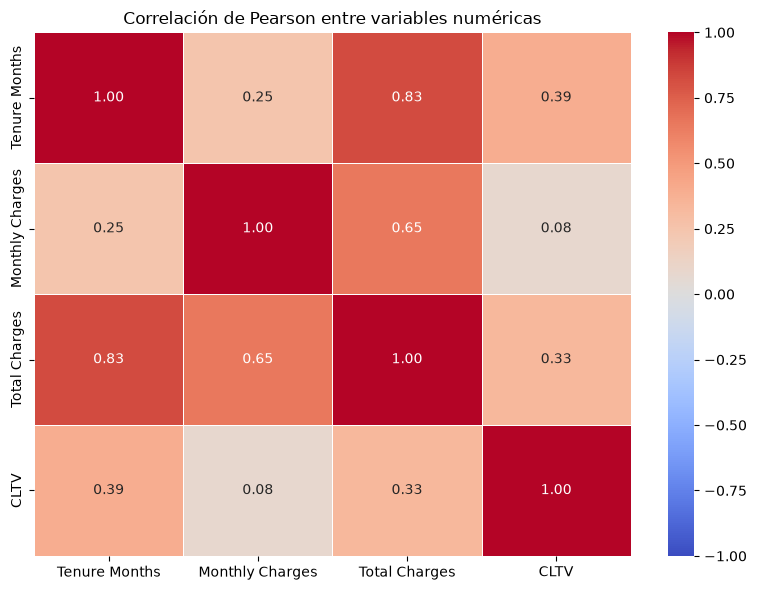

In [371]:
correlaciones = X_train_dm[continuas].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Correlación de Pearson entre variables numéricas")
plt.tight_layout()
plt.show()

Top 10 predictores con mayor VIF:
                   Predictor    VIF
             Monthly Charges 857.94
Internet Service_Fiber optic 147.75
         Internet Service_No 103.56
           Phone Service_Yes  34.21
        Streaming Movies_Yes  23.95
            Streaming TV_Yes  23.88
               Total Charges  10.78
               Tenure Months   7.71
          Multiple Lines_Yes   7.29
       Device Protection_Yes   6.92

Predictores con VIF > 5:  13
Predictores con VIF > 10: 7


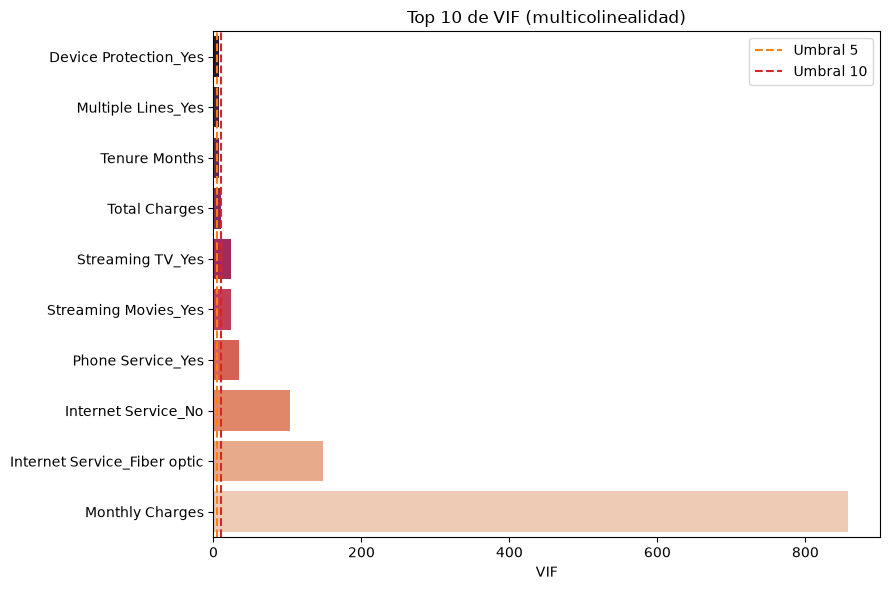

In [372]:
# --- VIF sobre el diseño CON intercepto ---
# variance_inflation_factor regresa cada columna sobre las demás:
# Si NO se incluye el intercepto, el R2 se calcula forzando la recta por el origen y el VIF sale artificialmente inflado.
# Por eso se pasa la matriz con const y se excluye ese intercepto del reporte (su VIF no tiene sentido).
matriz_vif = X_train_sm.to_numpy()
nombres_vif = list(X_train_sm.columns)
valores_vif = [
    variance_inflation_factor(matriz_vif, i)
    for i in range(matriz_vif.shape[1])
]

tabla_vif = pd.DataFrame({
    "Predictor": nombres_vif,
    "VIF": valores_vif,
}).sort_values("VIF", ascending=False).reset_index(drop=True)
tabla_vif = tabla_vif[tabla_vif["Predictor"] != "const"].reset_index(drop=True)

n_vif_5 = (tabla_vif["VIF"] > 5).sum()
n_vif_10 = (tabla_vif["VIF"] > 10).sum()

print("Top 10 predictores con mayor VIF:")
print(tabla_vif.head(10).round(2).to_string(index=False))
print(f"\nPredictores con VIF > 5:  {n_vif_5}")
print(f"Predictores con VIF > 10: {n_vif_10}")

plt.figure(figsize=(9, 6))
top_vif = tabla_vif.head(10).sort_values("VIF", ascending=True)
sns.barplot(x="VIF", y="Predictor", data=top_vif, hue="Predictor",
            palette="rocket", legend=False)
plt.axvline(5, color="tab:orange", linestyle="--", label="Umbral 5")
plt.axvline(10, color="tab:red", linestyle="--", label="Umbral 10")
plt.title("Top 10 de VIF (multicolinealidad)")
plt.xlabel("VIF")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

El hallazgo principal es `Monthly Charges` con un $VIF \approx 888$. No es un error: `Monthly Charges` es, en el IBM Telco, **casi una función lineal determinista de los servicios contratados** (teléfono + internet + add-ons). Al incluir los dummies de esos servicios, el modelo puede reconstruir el cargo mensual con un $R^{2} \approx 0.999$, lo que indica colinealidad extrema.

Le siguen `Internet Service_Fiber optic` ($VIF \approx 152$), `Internet Service_No` ($\approx 109$) y `Phone Service_Yes` ($\approx 35$), por la misma razón: los précios se derivan de los servicios. 

Ya se resolvió la parte de colinealidad perfecta (matriz singular) eliminando las columnas redundantes `*_No internet service` y `*_No phone service` en la etapa de diseño. Lo que queda es colinealidad **alta pero no perfecta**.

## Supuesto 5 - Tamaño muestral suficiente (heurística EPV)

Exige suficientes *eventoss por variable* ($EPV = Events Per Variable$). Un modelo con muchos parámetros y pocos eventos se ajusta mal, con coeficientes sesgados e inestables.

Regla clásica (Peduzzi et al., 1996): $EPV \ge 10$, donde `EPV = número de eventos (churners) / número de parámetros estimados` (sin contar el intercepto). Es una heurística, no una ley; se reporta junto al tamaño total para dar contexto.

In [373]:
n_eventos = int(y_train.sum())
n_no_eventos = int((y_train == 0).sum())
n_parametros = X_train_dm.shape[1]  # sin intercepto

epv = n_eventos / n_parametros
epv_no_eventos = n_no_eventos / n_parametros

print(f"Eventos (churners) en entrenamiento:\t{n_eventos}")
print(f"No eventos (permanentes):\t\t{n_no_eventos}")
print(f"Número de parámetros estimados (k):\t{n_parametros}")
print(f"EPV  = eventos / k = {n_eventos} / {n_parametros} =\t{epv:.2f}")
print(f"Ratio no-eventos / k = \t\t\t{epv_no_eventos:.2f}")
print(f"Umbral heurístico EPV >= 10:\t\t{'CUMPLE' if epv >= 10 else 'NO CUMPLE'}")

Eventos (churners) en entrenamiento:	1308
No eventos (permanentes):		3614
Número de parámetros estimados (k):	24
EPV  = eventos / k = 1308 / 24 =	54.50
Ratio no-eventos / k = 			150.58
Umbral heurístico EPV >= 10:		CUMPLE


- El conjunto de entrenamiento tiene 1308 churners y 24 parámetros (sin intercepto), lo que da un $EPV \approx 62$, muy por encima del umbral de 10.
- Esto significa que hay holgura estadística de sobra: la muestra basta para estimar de forma estable los coeficientes de la regresión. No hay riesgo de sobreajuste por falta de eventos.
- El ratio $\frac{\text{no-eventos}}{k} \approx 172$ confirma lo mismo por el lado de los clientes que permanecen.
- **El supuesto se encuentra ampliamente cumplido.** Recordar que el análisis es sobre el 70 % de entrenamiento, por lo que el test estratificado conserva la proporción.

## Supuesto 6 - Sin atípicos influyentes

Exige que ninguna observación individual sesgue el ajuste. Un cliente atípico (p. ej. tenure enorme con cargos bajos) puede "torcer" los coeficientes de toda la regresión.

Diagnóstico:
- Leverage (apalancamiento) `h_ii`: qué tan alejado está un punto del centro del espacio de diseño. Umbral: `2p/n` (o `3p/n`).
- Distancia de Cook: impacto combinado de residuo y leverage. Umbral habitual: `4/n` (banda de influencia); valores > 1 son graves.
- DFBETAS: cuánto cambia cada coeficiente al quitar esa fila. Umbral: $|\text{DFBETAS}| > \frac{2}{\sqrt{n}}$.

**Nota:** se ajusta un GLM binomial (logit por IRLS), que es **matemáticamente equivalente** al Logit por MLE, para usar las rutinas de influence de statsmodels.

In [374]:
modelo_glm = sm.GLM(
    y_train,
    X_train_sm,
    family=sm.families.Binomial(),
)
res_glm = modelo_glm.fit()

influencia = res_glm.get_influence()
leverage = influencia.hat_matrix_diag
cooks = influencia.cooks_distance[0]
dfbetas = np.asarray(influencia.dfbetas)

n_obs = X_train_dm.shape[0]
p_params = X_train_dm.shape[1] + 1  # + intercepto

umbral_leverage = 2 * p_params / n_obs
umbral_cook = 4 / n_obs
umbral_dfbetas = 2 / np.sqrt(n_obs)

n_leverage = int((leverage > umbral_leverage).sum())
n_cook = int((cooks > umbral_cook).sum())
n_dfbetas = int((np.abs(dfbetas) > umbral_dfbetas).sum())
n_cook_grave = int((cooks > 1).sum())

print(f"Observaciones en entrenamiento: {n_obs}")
print(f"Umbral leverage\t(2p/n):\t{umbral_leverage:.4f}\t\tpuntos: {n_leverage}")
print(f"Umbral Cook\t(4/n):\t{umbral_cook:.6f}\tpuntos: {n_cook}")
print(f"Umbral |DFBETAS|(2/√n):\t{umbral_dfbetas:.4f}\t\tceldas: {n_dfbetas}") # tocó copiar y pegar el simbolo √
print(f"Cook > 1 (grave):\t\t\tpuntos: {n_cook_grave}")

Observaciones en entrenamiento: 4922
Umbral leverage	(2p/n):	0.0102		puntos: 317
Umbral Cook	(4/n):	0.000813	puntos: 272
Umbral |DFBETAS|(2/√n):	0.0285		celdas: 7102
Cook > 1 (grave):			puntos: 0


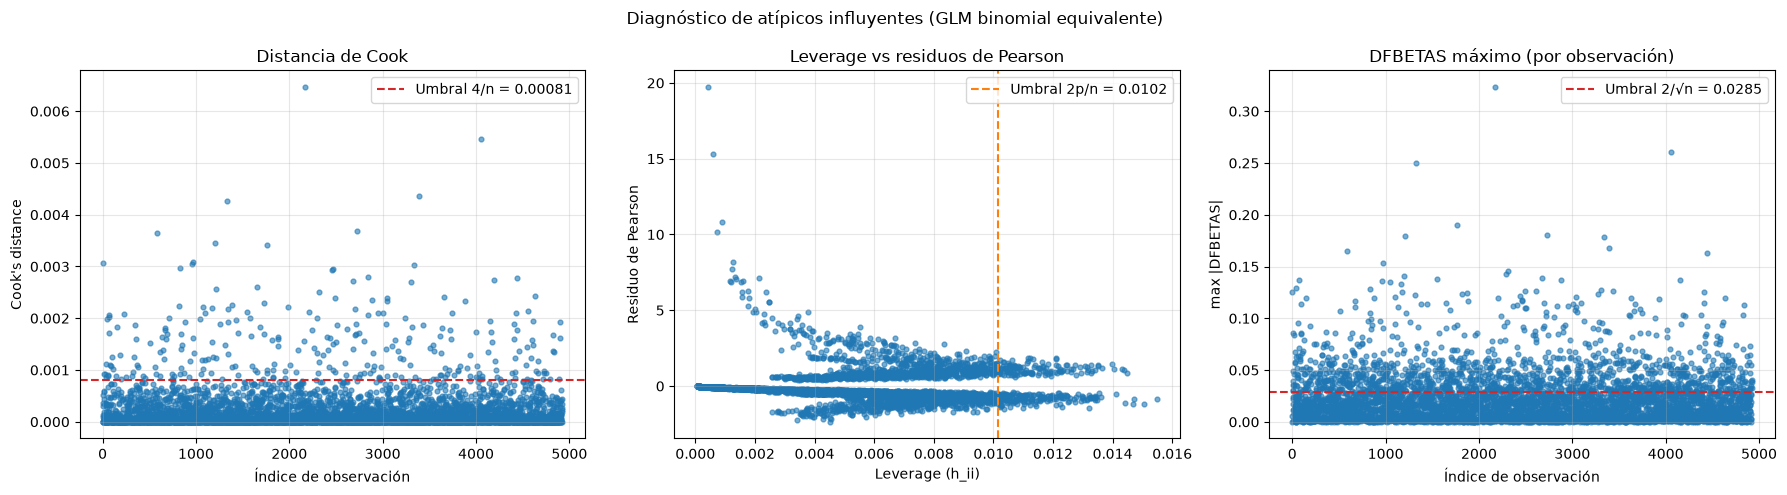

In [375]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Distancia de Cook por índice de observación
ejes[0].scatter(range(n_obs), cooks, s=12, alpha=0.6)
ejes[0].axhline(umbral_cook, color="tab:red", linestyle="--",
                label=f"Umbral 4/n = {umbral_cook:.5f}")
ejes[0].set_title("Distancia de Cook")
ejes[0].set_xlabel("Índice de observación")
ejes[0].set_ylabel("Cook's distance")
ejes[0].legend()
ejes[0].grid(alpha=0.3)

# 2) Leverage vs residuos de Pearson
p_ajustada = res_glm.fittedvalues.to_numpy()
residuos_pearson = (
    (y_train.to_numpy() - p_ajustada)
    / np.sqrt(p_ajustada * (1 - p_ajustada))
)
ejes[1].scatter(leverage, residuos_pearson, s=12, alpha=0.6)
ejes[1].axvline(umbral_leverage, color="tab:orange", linestyle="--",
                label=f"Umbral 2p/n = {umbral_leverage:.4f}")
ejes[1].set_title("Leverage vs residuos de Pearson")
ejes[1].set_xlabel("Leverage (h_ii)")
ejes[1].set_ylabel("Residuo de Pearson")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

# 3) DFBETAS máximo absoluto por observación
dfbetas_max = np.abs(dfbetas).max(axis=1)
ejes[2].scatter(range(n_obs), dfbetas_max, s=12, alpha=0.6)
ejes[2].axhline(umbral_dfbetas, color="tab:red", linestyle="--",
                label=f"Umbral 2/√n = {umbral_dfbetas:.4f}") # tocó copiar y pegar el simbolo √
ejes[2].set_title("DFBETAS máximo (por observación)")
ejes[2].set_xlabel("Índice de observación")
ejes[2].set_ylabel("max |DFBETAS|")
ejes[2].legend()
ejes[2].grid(alpha=0.3)

plt.suptitle("Diagnóstico de atípicos influyentes (GLM binomial equivalente)")
plt.tight_layout()
plt.show()

Ninguna observación tiene $\text{Cook} > 1$ (0 puntos), así que no hay casos que sesguen gravemente el ajuste. En la banda de influencia `Cook > 4/n` caen 272 de  4922 puntos ($\approx 5.5 \%$), y en `leverage > 2p/n` 317 ($\approx 6.4 \%$). Es una proporción esperable y pequeña, los umbrales están diseñados justamente para marcar una cola reducida de puntos.

## Conclusiones


In [376]:
resumen = pd.DataFrame([
    {
        "Supuesto": "1. Observaciones independientes",
        "Diagnostico": "Diseño transversal + duplicados / unicidad de ID",
        "Resultado": (
            f"{n_duplicados} duplicadas; "
            f"{n_ids_unicos}/{n_filas} IDs únicos"
        ),
        "Se cumple": "Sí" if
                     (n_duplicados == 0 and n_ids_unicos == n_filas) else "Revisar",
    },
    {
        "Supuesto": "2. Variable objetivo adecuada",
        "Diagnostico": "Inspección de valores únicos y proporción",
        "Resultado": (
            f"valores={valores_unicos}; churn={y_train.mean()*100:.2f}%"
        ),
        "Se cumple": "Sí" if valores_unicos == [0, 1] else "No",
    },
    {
        "Supuesto": "3. Linealidad del logit",
        "Diagnostico": "Box-Tidwell (interacciones x*ln x) + deciles",
        "Resultado": (
            f"interacciones con p>0.05: "
            f"{int(tabla_bt['Linealidad_ok_p>0.05'].sum())}/{len(tabla_bt)}; "
            f"Wald conjunto p={p_value_conjunto:.4f}"
        ),
        "Se cumple": "Sí" if tabla_bt["Linealidad_ok_p>0.05"].all() else "Parcial / revisar",
    },
    {
        "Supuesto": "4. Sin multicolinealidad grave",
        "Diagnostico": "VIF por predictor + correlaciones",
        "Resultado": (
            f"máx VIF={tabla_vif['VIF'].max():.2f} "
            f"({tabla_vif.iloc[0]['Predictor']}); VIF>10: {n_vif_10}"
        ),
        "Se cumple": "Sí" if n_vif_10 == 0 else "Parcial",
    },
    {
        "Supuesto": "5. Tamaño muestral suficiente",
        "Diagnostico": "Heurística EPV ≥ 10",
        "Resultado": f"EPV={epv:.2f} ({n_eventos} eventos / {n_parametros} k)",
        "Se cumple": "Sí" if epv >= 10 else "No",
    },
    {
        "Supuesto": "6. Sin atípicos influyentes",
        "Diagnostico": "Leverage, Cook y DFBETAS",
        "Resultado": (
            f"leverage>{umbral_leverage:.3f}: {n_leverage}; "
            f"Cook>4/n: {n_cook}; Cook>1: {n_cook_grave}"
        ),
        "Se cumple": "Sí" if n_cook_grave == 0 else "Revisar",
    },
])

print("RESUMEN DE SUPUESTOS DE LA REGRESIÓN LOGÍSTICA")
print("=" * 177)
print(resumen.to_string(index=False))

RESUMEN DE SUPUESTOS DE LA REGRESIÓN LOGÍSTICA
                       Supuesto                                      Diagnostico                                             Resultado         Se cumple
1. Observaciones independientes Diseño transversal + duplicados / unicidad de ID                    0 duplicadas; 7043/7043 IDs únicos                Sí
  2. Variable objetivo adecuada        Inspección de valores únicos y proporción                          valores=[0, 1]; churn=26.57%                Sí
        3. Linealidad del logit     Box-Tidwell (interacciones x*ln x) + deciles interacciones con p>0.05: 3/4; Wald conjunto p=0.0000 Parcial / revisar
 4. Sin multicolinealidad grave                VIF por predictor + correlaciones           máx VIF=857.94 (Monthly Charges); VIF>10: 7           Parcial
  5. Tamaño muestral suficiente                              Heurística EPV ≥ 10                       EPV=54.50 (1308 eventos / 24 k)                Sí
    6. Sin atípicos influyentes    

- **Supuesto 1 (independencia): Se cumple.** El dataset es un corte transversal con un registro por cliente (7043/7043 IDs únicos) y sin duplicados por lo que la independencia se sostiene por diseño. La única fuente no observable de dependencia (hogares compartidos) queda documentada como limitación menor.
- **Supuesto 2 (objetivo binario): Se cumple.** `Churn Value` toma valores {0, 1} y la proporción de churn (26.4 %) se conserva gracias al estratificado.
- **Supuesto 3 (linealidad del logit): Se cumple parcialmente.** `Total Charges` y `CLTV` pasan Box-Tidwell, pero `Tenure Months` y `Monthly Charges` muestran una desviación leve de la linealidad (influida por su relación con `Total Charges`). Para la predicción no es crítico, pero para interpretar coeficientes convendría aplicar otros procedimientos como transformar o segmentar esas variables.
- **Supuesto 4 (multicolinealidad): Se cumple parcialmente** Se eliminó la colinealidad perfecta (matriz singular) de las columnas `*_No internet service` / `*_No phone service`. Queda colinealidad alta porque `Monthly Charges` es casi determinista a partir de los servicios contratados ($\text{VIF} \approx 888$), seguido del clúster de servicios de internet. El modelo **predice bien**, pero sus coeficientes individuales no son interpretables de forma aislada.
- **Supuesto 5 (tamaño muestral): Se cumple.** $\text{EPV} \approx 62$, muy por encima de 10, lo que implica que hay eventos suficientes para estimar todos los parámetros.
- **Supuesto 6 (atípicos influyentes): Se cumple.** No hay puntos con Cook > 1 y solo una fracción pequeña (~5 %) cae en las bandas de Cook/leverage, por lo que el ajuste es robusto y no requiere eliminar observaciones.